In [1]:
import sys
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score
import os
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from collections import Counter


## Paso 1: Cargar el corpus y reutilizar el preprocesamiento

**Objetivo:** reusar lo que ya construimos en el Módulo 2, sin empezar de nuevo.

**Que hacemos**
- Cargamos `ag_news_train.csv` y `ag_news_test.csv`, el mismo corpus del Módulo 2.
- Importamos desde `src/preprocesamiento.py` las funciones de limpieza y lematización ya escritas (`limpiar_texto`, `lematizar`).

**Resultado**
- Train: 8000 noticias. Test: 2000 noticias. Columnas `text` y `label`, sin nulos.
- Clases balanceadas: 2000 noticias por clase en train y 500 en test.
- Después del preprocesamiento no queda ningún documento vacío. El promedio es de 23 tokens por noticia y el máximo es de 70 en train y 77 en test.
- El texto original pasa de tener ruido a una versión limpia y lematizada en la columna `processed`.

> El preprocesamiento trabaja documento por documento y no calcula estadísticas del corpus, por eso se puede aplicar a train y test sin generar fuga de datos

In [2]:
train_df = pd.read_csv("../data/ag_news/ag_news_train.csv")
test_df = pd.read_csv("../data/ag_news/ag_news_test.csv")

print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Columnas:", train_df.columns.tolist())
print("Nulos en train:", train_df.isna().sum().sum(), "| Nulos en test:", test_df.isna().sum().sum())

print("\nDocumentos por clase (train):")
print(train_df["label"].value_counts())
print("\nDocumentos por clase (test):")
print(test_df["label"].value_counts())

Train: (8000, 2) | Test: (2000, 2)
Columnas: ['text', 'label']
Nulos en train: 0 | Nulos en test: 0

Documentos por clase (train):
label
Sci_Tech    2000
Business    2000
Sports      2000
World       2000
Name: count, dtype: int64

Documentos por clase (test):
label
World       500
Business    500
Sports      500
Sci_Tech    500
Name: count, dtype: int64


In [3]:
sys.path.append("../src")

from preprocesamiento import limpiar_texto, lematizar, preprocess_text

In [4]:
for df in (train_df, test_df):
    df["clean"] = df["text"].apply(limpiar_texto)
    df["processed"] = df["clean"].apply(lematizar)

for nombre, df in [("train", train_df), ("test", test_df)]:
    n_tok = df["processed"].str.split().str.len()
    print(f"{nombre}: documentos vacíos = {(n_tok == 0).sum()} | tokens medios = {n_tok.mean():.1f} | máx = {n_tok.max()}")

for i in range(2):
    print("\nORIGINAL :", test_df["text"][i][:150])
    print("PROCESADO:", test_df["processed"][i][:150])

train: documentos vacíos = 0 | tokens medios = 23.0 | máx = 70
test: documentos vacíos = 0 | tokens medios = 23.0 | máx = 77

ORIGINAL : BSkyB sees profits rise after strong subscriber growth (AFP). AFP - British satellite broadcaster BSkyB said profit rose by 16 percent in the first qu
PROCESADO: bskyb see profit rise strong subscriber growth british satellite broadcaster bskyb say profit rise percent quarter group enjoy strong subscriber growt

ORIGINAL : Before-the Bell; Rouse Co. Shares Jump. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=RSE.N target=/stocks/quickinfo/fullquote"&gt
PROCESADO: bell rouse co share jump rse jump bell general growth property inc ggp shopping mall owner friday say buy rouse billion


In [5]:
def n_tokens(df):
    return df["processed"].str.split().str.len()

resumen = pd.DataFrame({
    "conjunto": ["train", "test"],
    "documentos": [len(train_df), len(test_df)],
    "clases": [train_df["label"].nunique(), test_df["label"].nunique()],
    "tokens_totales": [n_tokens(train_df).sum(), n_tokens(test_df).sum()],
    "tokens_medios": [round(n_tokens(train_df).mean(), 1), round(n_tokens(test_df).mean(), 1)],
    "tokens_max": [n_tokens(train_df).max(), n_tokens(test_df).max()],
})
display(resumen)

,conjunto,documentos,clases,tokens_totales,tokens_medios,tokens_max
0,train,8000,4,184366,23.0,70
1,test,2000,4,46023,23.0,77


## Paso 2: Separar train y test antes de vectorizar

**Objetivo:** que el vectorizador nunca llegue a ver el conjunto de prueba.

**Que hacemos**
- Usamos los splits provistos por la cátedra (`ag_news_train.csv` y `ag_news_test.csv`), así que no hace falta `train_test_split`.
- Dejamos el test aparte antes de calcular cualquier estadística del corpus: todavia no se vectorizo nada.
- Verificamos que las clases de train y test coincidan y que no haya noticias repetidas entre ambos.

**el `fit` va solo en el train**
`TfidfVectorizer` aprende dos cosas al ajustarse: el vocabulario y los pesos IDF, y dependen de en cuántos documentos aparece cada término. Si se ajusta con el test, el modelo recibice información del conjunto con el que después se lo evalúa (data leakage) y las métricas salen infladas. Por eso el `fit` se hace solo sobre el train y sobre el test se aplica únicamente `transform`.

**Resultado**
- `X_train` (8000), `X_test` (2000), con sus etiquetas.
- Mismas 4 clases en ambos conjuntos y 0 noticias repetidas entre train y test.

In [6]:
X_train = train_df["processed"]
y_train = train_df["label"]
X_test = test_df["processed"]
y_test = test_df["label"]

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Clases en train:", sorted(y_train.unique()))
print("Clases en test :", sorted(y_test.unique()))
assert set(y_train.unique()) == set(y_test.unique())

Train: (8000,) | Test: (2000,)
Clases en train: ['Business', 'Sci_Tech', 'Sports', 'World']
Clases en test : ['Business', 'Sci_Tech', 'Sports', 'World']


In [7]:
repetidas = set(train_df["text"]) & set(test_df["text"])
print("Noticias repetidas entre train y test:", len(repetidas))

Noticias repetidas entre train y test: 0


In [8]:
# Vocabulario construido SOLO con train; se mide qué parte del texto de test cubre
tokens_train = Counter(t for doc in train_df["processed"] for t in doc.split())
tokens_test = [t for doc in test_df["processed"] for t in doc.split()]

print("Palabras distintas en train:", len(tokens_train))
for N in [1000, 5000, 20000]:
    vocab = {w for w, _ in tokens_train.most_common(N)}
    cobertura = sum(t in vocab for t in tokens_test) / len(tokens_test)
    print(f"Vocabulario de {N:>6} palabras -> cubre {cobertura:.1%} de los tokens del test")

Palabras distintas en train: 16845
Vocabulario de   1000 palabras -> cubre 59.6% de los tokens del test
Vocabulario de   5000 palabras -> cubre 86.8% de los tokens del test
Vocabulario de  20000 palabras -> cubre 95.3% de los tokens del test


## Paso 3: Vectorización TF-IDF

**Objetivo:** convertir el texto en una matriz TF-IDF bajo control.

**Que hacemos**
- Experimentamos con `ngram_range` (solo unigramas vs. unigramas y bigramas) y con `max_features` (1000, 5000, 20000 y sin límite).
- Para elegir los parámetros usamos validación cruzada estratificada de 5 folds **dentro del train**, con la métrica F1 macro. El test no se toca para decidir.
- Usamos un `Pipeline` para que el vectorizador se ajuste en cada fold solo con la parte de entrenamiento de ese fold, y que la validación cruzada tampoco filtre datos.
- Con la configuración elegida aplicamos `fit_transform` sobre el train y solo `transform` sobre el test.

**Resultados de los experimentos** (Regresión Logística como modelo de prueba)

| ngram_range | max_features | F1 macro (CV) | Desvío |
|---|---|---|---|
| (1, 2) | 20000 | 0.8824 | 0.0078 |
| (1, 1) | sin límite | 0.8815 | 0.0065 |
| (1, 1) | 20000 | 0.8815 | 0.0065 |
| (1, 1) | 5000 | 0.8801 | 0.0077 |
| (1, 2) | sin límite | 0.8801 | 0.0087 |
| (1, 2) | 5000 | 0.8797 | 0.0066 |
| (1, 1) | 1000 | 0.8565 | 0.0069 |
| (1, 2) | 1000 | 0.8542 | 0.0077 |

- Con 1000 términos el desempeño cae unos 2.5 puntos: el vocabulario es demasiado chico.
- A partir de 5000 términos las configuraciones quedan empatadas: la diferencia entre la mejor y la peor es de 0.003, menor que el desvío entre folds.
- Los unigramas con 20000 términos y sin límite dan exactamente lo mismo, lo que indica que el vocabulario de unigramas del train tiene menos de 20000 términos.
- No limitar el vocabulario con bigramas no mejora el resultado y genera una matriz mucho más grande.
- Elegimos **`ngram_range=(1, 2)` y `max_features=20000`**: es la mejor combinación de la tabla. Los bigramas aportan expresiones con significado propio, como `abu ghraib` o `abn amro`.

**Resultado**
- Matriz de train: (8000, 20000). Matriz de test: (2000, 20000).
- Ambas son matrices esparsas (`csr_matrix`) con el mismo vocabulario. La densidad del train es de solo 0.12 %: el 99.9 % de las celdas son ceros.

In [9]:
# PASO 2 y 3
# Validación cruzada DENTRO del train: el test no se toca para elegir parámetros.
# Se usa un Pipeline para que el vectorizador se ajuste en cada fold solo con
# la parte de entrenamiento de ese fold (así la validación cruzada tampoco filtra datos).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados = []
for ngram in [(1, 1), (1, 2)]:
    for max_feat in [1000, 5000, 20000, None]:
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=max_feat, ngram_range=ngram)),
            ("clf", LogisticRegression(max_iter=1000)),
        ])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
        resultados.append({
            "ngram_range": ngram,
            "max_features": max_feat if max_feat else "sin límite",
            "f1_macro_cv": round(scores.mean(), 4),
            "desvío": round(scores.std(), 4),
        })

tabla = pd.DataFrame(resultados).sort_values("f1_macro_cv", ascending=False)
display(tabla)

,ngram_range,max_features,f1_macro_cv,desvío
6,"(1, 2)",20000,0.8824,0.0078
3,"(1, 1)",sin límite,0.8815,0.0065
2,"(1, 1)",20000,0.8815,0.0065
1,"(1, 1)",5000,0.8801,0.0077
7,"(1, 2)",sin límite,0.8801,0.0087
5,"(1, 2)",5000,0.8797,0.0066
0,"(1, 1)",1000,0.8565,0.0069
4,"(1, 2)",1000,0.8542,0.0077


In [10]:
NGRAM = (1, 2)          # unigramas y bigramas
MAX_FEATURES = 20000    # ajustalo según la tabla

vectorizer = TfidfVectorizer(max_features=MAX_FEATURES, ngram_range=NGRAM)

# fit_transform SOLO sobre el train: aprende vocabulario e IDF únicamente de acá
X_train_tfidf = vectorizer.fit_transform(X_train)

# transform sobre el test: usa el vocabulario y los pesos ya aprendidos, sin reajustar
X_test_tfidf = vectorizer.transform(X_test)

In [11]:
print("Train:", X_train_tfidf.shape, "| Test:", X_test_tfidf.shape)
print("Tipo:", type(X_train_tfidf))

densidad = X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])
print(f"Densidad del train: {densidad:.4%} (el resto son ceros)")

# Mismas columnas (mismo vocabulario) y una fila por noticia
assert X_train_tfidf.shape[1] == X_test_tfidf.shape[1] == len(vectorizer.vocabulary_)
assert X_train_tfidf.shape[0] == len(X_train) and X_test_tfidf.shape[0] == len(X_test)

terminos = vectorizer.get_feature_names_out()
print("Ejemplos de bigramas:", [t for t in terminos if " " in t][:10])

Train: (8000, 20000) | Test: (2000, 20000)
Tipo: <class 'scipy.sparse._csr.csr_matrix'>
Densidad del train: 0.1203% (el resto son ceros)
Ejemplos de bigramas: ['aaron peirsol', 'abandon sensitive', 'abbey national', 'abidjan ivory', 'ability run', 'abn amro', 'abu ghraib', 'abu musab', 'abuse iraqi', 'abuse policy']


## Paso 4: Modelo de referencia (baseline)

**Objetivo:** entrenar un clasificador de referencia y que corra entero.

**Qué hacemos**
- Comparamos tres clasificadores clásicos sobre la misma matriz TF-IDF, con la misma validación cruzada dentro del train:

| Modelo | F1 macro (CV) | Desvío |
|---|---|---|
| Naive Bayes | 0.8882 | 0.0074 |
| SVM lineal | 0.8842 | 0.0062 |
| Regresión Logística | 0.8824 | 0.0078 |

- Entrenamos el modelo elegido solo con el train y predecimos sobre el test, que el modelo nunca vio.

**Por qué Regresión Logística**
- Los tres modelos quedan prácticamente empatados: la diferencia entre el primero y el último es de 0.006, menos que el desvío entre folds. Ninguno es claramente mejor.
- Entonces desempatamos por otros criterios:
  - **Interpretabilidad:** sus coeficientes por clase permiten ver qué términos pesan más para cada categoría (lo usamos al final del notebook).
  - **Probabilidades:** entrega probabilidades por clase, útiles para los próximos checkpoints.
  - **Estabilidad:** funciona bien con matrices esparsas de muchas dimensiones y trae regularización L2 por defecto.
- Naive Bayes es una alternativa válida y con un score apenas superior.
- Una limitación: el vectorizador se eligió en el paso 3 usando Regresión Logística, lo que podría favorecer levemente a este modelo en la comparación.

**Resultado**
- Baseline entrenado y 2000 predicciones sobre el test.
- Predicciones por clase: Business 515, Sports 506, Sci_Tech 500, World 479. Son valores cercanos a las 500 noticias reales por clase, así que el modelo no está sesgado hacia ninguna.

In [12]:
modelos = {
    "Naive Bayes": MultinomialNB(),
    "Regresión Logística": LogisticRegression(max_iter=1000),
    "SVM lineal": LinearSVC(random_state=42),
}

# Mismo vectorizador elegido en el paso 3, dentro de un Pipeline (sin fuga entre folds)
comparacion = []
for nombre, clf in modelos.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=MAX_FEATURES, ngram_range=NGRAM)),
        ("clf", clf),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
    comparacion.append({"modelo": nombre, "f1_macro_cv": round(scores.mean(), 4), "desvío": round(scores.std(), 4)})

display(pd.DataFrame(comparacion).sort_values("f1_macro_cv", ascending=False))

,modelo,f1_macro_cv,desvío
0,Naive Bayes,0.8882,0.0074
2,SVM lineal,0.8842,0.0062
1,Regresión Logística,0.8824,0.0078


In [13]:
# Modelo de referencia: Regresión Logística sobre la matriz esparsa TF-IDF
modelo = LogisticRegression(max_iter=1000, random_state=42)

# Entrena SOLO con el train
modelo.fit(X_train_tfidf, y_train)

# Predice sobre el test (el modelo nunca lo vio durante el entrenamiento)
y_pred = modelo.predict(X_test_tfidf)

In [14]:
print("Clases aprendidas:", modelo.classes_)
print("Predicciones:", y_pred.shape, "| Test real:", y_test.shape)
assert len(y_pred) == len(y_test)

print("\nPredicciones por clase:")
print(pd.Series(y_pred).value_counts())

for i in range(3):
    print(f"\nTexto : {test_df['text'][i][:120]}")
    print(f"Real  : {y_test.iloc[i]} | Predicho: {y_pred[i]}")

Clases aprendidas: ['Business' 'Sci_Tech' 'Sports' 'World']
Predicciones: (2000,) | Test real: (2000,)

Predicciones por clase:
Business    515
Sports      506
Sci_Tech    500
World       479
Name: count, dtype: int64

Texto : BSkyB sees profits rise after strong subscriber growth (AFP). AFP - British satellite broadcaster BSkyB said profit rose
Real  : World | Predicho: Business

Texto : Before-the Bell; Rouse Co. Shares Jump. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=RSE.N target=/
Real  : Business | Predicho: Business

Texto : Minutemen KO'd by Dukes. HARRISONBURG, Va. -- Opposing running backs are beginning to enjoy playing against the Universi
Real  : Sports | Predicho: Sports


## Paso 5: Evaluación sobre el test

**Objetivo:** medir el desempeño con datos que el modelo nunca vio y entender dónde se equivoca.

**Resultados** (accuracy: 0.8895, F1 macro: 0.890)

| Clase | Precision | Recall | F1 |
|---|---|---|---|
| Business | 0.829 | 0.854 | 0.841 |
| Sci_Tech | 0.874 | 0.874 | 0.874 |
| Sports | 0.949 | 0.960 | 0.954 |
| World | 0.908 | 0.870 | 0.889 |

El F1 macro en test (0.890) es coherente con el de la validación cruzada (0.882): el resultado es estable y no hay señales de que el modelo se haya ajustado al test.

**Análisis de la matriz de confusion**
- **Sports** es la clase más fácil (F1 0.954): tiene un vocabulario muy propio (`team`, `coach`, `game`, `season`).
- **Business** es la más difícil (F1 0.841). Las confusiones más frecuentes son Sci_Tech → Business (46 casos), Business → Sci_Tech (41), World → Business (33) y Business → World (26): noticias de empresas tecnológicas o de economía internacional que comparten vocabulario con otras categorías.
- Algunos errores son discutibles: por ejemplo, una nota de béisbol y una de cricket figuran como `World` en el dataset y el modelo las predijo como `Sports`.

**Términos más influyentes por clase** (coeficientes de la regresión)
- Business: `company`, `oil`, `profit`, `billion`.
- Sci_Tech: `internet`, `space`, `microsoft`, `software`.
- Sports: `team`, `coach`, `game`, `season`.
- World: `iraq`, `president`, `minister`, `election`.

In [15]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, digits=3))

Accuracy: 0.8895

              precision    recall  f1-score   support

    Business      0.829     0.854     0.841       500
    Sci_Tech      0.874     0.874     0.874       500
      Sports      0.949     0.960     0.954       500
       World      0.908     0.870     0.889       500

    accuracy                          0.889      2000
   macro avg      0.890     0.889     0.890      2000
weighted avg      0.890     0.889     0.890      2000



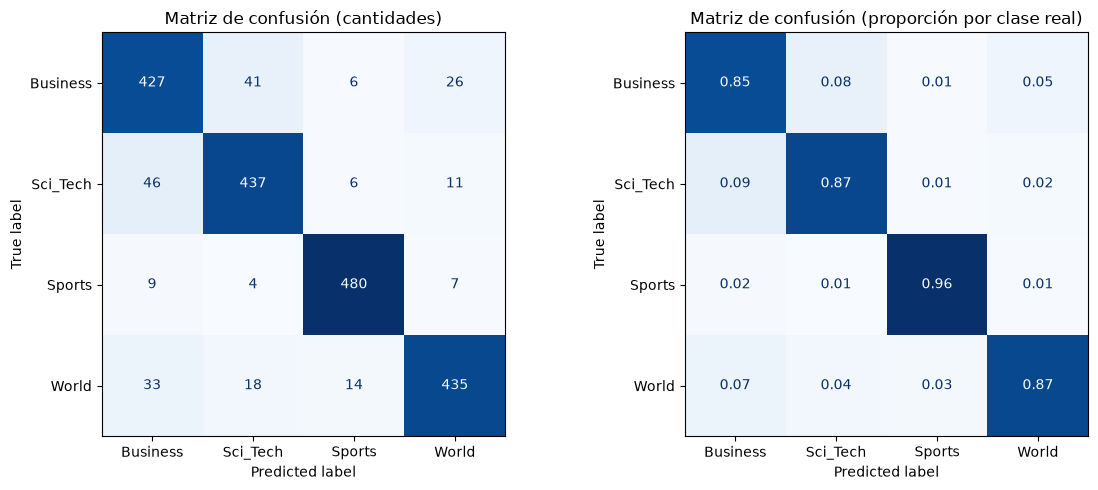

In [16]:
clases = modelo.classes_
cm = confusion_matrix(y_test, y_pred, labels=clases)                     # conteos
cm_norm = confusion_matrix(y_test, y_pred, labels=clases, normalize="true")  # % por fila (recall)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm, display_labels=clases).plot(ax=ejes[0], cmap="Blues", colorbar=False)
ejes[0].set_title("Matriz de confusión (cantidades)")
ConfusionMatrixDisplay(cm_norm, display_labels=clases).plot(ax=ejes[1], cmap="Blues", colorbar=False, values_format=".2f")
ejes[1].set_title("Matriz de confusión (proporción por clase real)")
plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/matriz_confusion.png", dpi=200)
plt.show()

In [17]:
errores = []
for i, real in enumerate(clases):
    for j, pred in enumerate(clases):
        if i != j and cm[i, j] > 0:
            errores.append({"real": real, "predicho": pred, "cantidad": int(cm[i, j])})

display(pd.DataFrame(errores).sort_values("cantidad", ascending=False))

,real,predicho,cantidad
3,Sci_Tech,Business,46
0,Business,Sci_Tech,41
9,World,Business,33
2,Business,World,26
10,World,Sci_Tech,18
11,World,Sports,14
5,Sci_Tech,World,11
6,Sports,Business,9
8,Sports,World,7
1,Business,Sports,6


In [18]:
mal = test_df[y_test.values != y_pred].copy()
mal["predicho"] = y_pred[y_test.values != y_pred]

for _, fila in mal.head(6).iterrows():
    print(f"Real: {fila['label']} | Predicho: {fila['predicho']}")
    print(fila["text"][:200], "\n")

Real: World | Predicho: Business
BSkyB sees profits rise after strong subscriber growth (AFP). AFP - British satellite broadcaster BSkyB said profit rose by 16 percent in the first quarter as the group enjoyed strong subscriber growt 

Real: World | Predicho: Business
Producer sues for Rings profits. Hollywood producer Saul Zaentz sues the producers of The Lord of the Rings for $20m in royalties. 

Real: Business | Predicho: World
EU, US Talks on Aircraft Aid Grounded. US and EU negotiators disagreed on Thursday about state aid for aircraft rivals Airbus and Boeing, winding up no closer on a sensitive issue that has gathered st 

Real: World | Predicho: Sports
Maddux Wins No. 302, Baker Wins No. 1,000. Greg Maddux pitched the Chicago Cubs into the lead in the NL wild-card race and gave Dusty Baker a win to remember. Maddux threw seven shutout innings for hi 

Real: World | Predicho: Sports
Democrat Seeks to End Iowa, N.H. Power (AP). AP - If Simon Rosenberg decides to run for Democrati

In [19]:
terminos = vectorizer.get_feature_names_out()
for k, clase in enumerate(clases):
    top = modelo.coef_[k].argsort()[::-1][:8]
    print(clase, "->", [terminos[t] for t in top])

Business -> ['company', 'oil', 'profit', 'inc', 'billion', 'economy', 'buy', 'co']
Sci_Tech -> ['internet', 'space', 'microsoft', 'software', 'scientist', 'computer', 'nasa', 'technology']
Sports -> ['team', 'coach', 'game', 'win', 'season', 'cup', 'league', 'player']
World -> ['iraq', 'president', 'kill', 'leader', 'minister', 'nuclear', 'election', 'un']
